In [4]:
from typing import TypedDict, Literal


class PortfolioState(TypedDict):
    amount_usd: float
    total_usd_after_interest: float
    total: float
    currency: Literal["INR", "EUR"]

In [6]:
def calculate_total_usd(state: PortfolioState) -> PortfolioState:
    state["total_usd_after_interest"] = state["amount_usd"] * 1.08
    return state


def calculate_total_inr(state: PortfolioState) -> PortfolioState:
    exchange_rate = 94.94
    state["total"] = state["total_usd_after_interest"] * exchange_rate
    return state

def calculate_total_eur(state: PortfolioState) -> PortfolioState:
    exchange_rate = 0.90
    state["total"] = state["total_usd_after_interest"] * exchange_rate
    return state

def choose_currency(state: PortfolioState) -> str:
    return state["currency"]


In [8]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PortfolioState)
builder.add_node("calculate_total_usd_node", calculate_total_usd)
builder.add_node("calculate_total_inr_node", calculate_total_inr)

builder.add_node("calculate_total_eur_node", calculate_total_eur)

builder.add_edge(START, "calculate_total_usd_node")
builder.add_conditional_edges("calculate_total_usd_node",choose_currency, {
    "EUR": "calculate_total_eur_node",
    "INR": "calculate_total_inr_node"
})
builder.add_edge("calculate_total_inr_node", END)
builder.add_edge("calculate_total_eur_node", END)

graph = builder.compile()


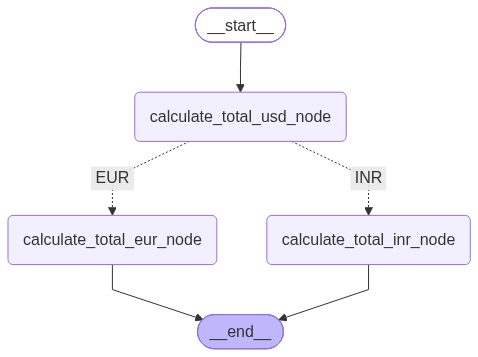

In [9]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
graph.invoke({"amount_usd": 100, "currency": "EUR"})

{'amount_usd': 100,
 'total_usd_after_interest': 108.0,
 'total': 97.2,
 'currency': 'EUR'}